# EDA — 04. Análisis de Features Categóricas y Binarias

**Proyecto Final — Uplift Modeling | CAECE**

---

## Objetivo

Análisis exhaustivo de las seis features no-numéricas del dataset:

| Variable | Tipo | Categorías |
|----------|------|-----------|
| `history_segment` | Categórica ordinal | 7 niveles de gasto |
| `zip_code` | Categórica nominal | 3 zonas geográficas |
| `channel` | Categórica nominal | 3 canales de compra |
| `mens` | Binaria | 0/1 — historial moda masculina |
| `womens` | Binaria | 0/1 — historial moda femenina |
| `newbie` | Binaria | 0/1 — cliente nuevo |

Se cubren: análisis univariado, bivariado con targets, asociación entre features (Cramér's V),
poder predictivo individual (AUC-ROC) y selección de features con **Boruta** sobre todas las variables del dataset.

---

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score
from IPython.display import display

warnings.filterwarnings("ignore")
try:    plt.style.use("seaborn-v0_8-whitegrid")
except: plt.style.use("seaborn-whitegrid")
sns.set_palette("Set2")
PALETTE = sns.color_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv(os.path.join("..", "..", "data", "raw", "hillstrom.csv"))

CAT_ORDINAL   = ["history_segment"]
CAT_NOMINAL   = ["zip_code", "channel"]
BIN_FEATURES  = ["mens", "womens", "newbie"]
ALL_CAT       = CAT_ORDINAL + CAT_NOMINAL + BIN_FEATURES
NUM_FEATURES  = ["recency", "history"]
ALL_FEATURES  = NUM_FEATURES + ALL_CAT
BINARY_TGT    = ["visit", "conversion"]
ALL_TGT       = ["visit", "conversion", "spend"]
SEGMENT_COL   = "segment"

HS_ORDER = ["1) $0 - $100","2) $100 - $200","3) $200 - $350",
            "4) $350 - $500","5) $500 - $750","6) $750 - $1,000","7) $1,000 +"]

print(f"Dataset: {df.shape[0]:,} × {df.shape[1]}")
print(f"Features categóricas/binarias: {ALL_CAT}")

Dataset: 64,000 × 12
Features categóricas/binarias: ['history_segment', 'zip_code', 'channel', 'mens', 'womens', 'newbie']


## 1. Análisis Univariado — Variables Categóricas Nominales y Ordinales

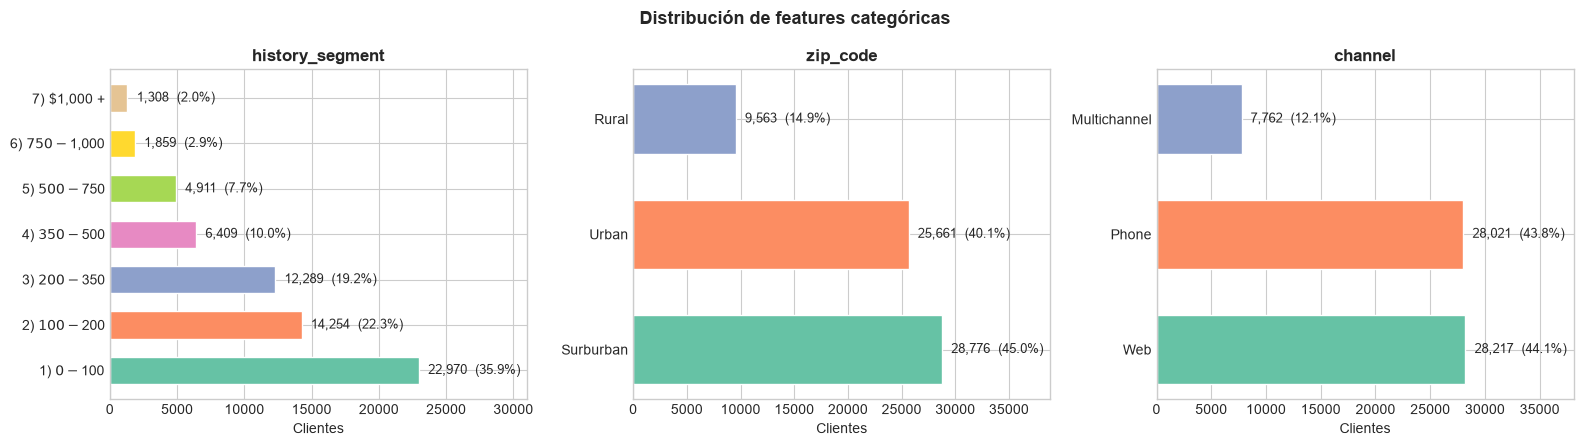

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col, order in zip(
    axes,
    ["history_segment", "zip_code", "channel"],
    [HS_ORDER, None, None]
):
    vc = df[col].value_counts()
    if order:
        vc = vc.reindex(order).dropna()
    cats = vc.index.tolist()
    bars = ax.barh(cats, vc.values, color=PALETTE[:len(cats)], edgecolor="white", height=0.6)
    for bar, v in zip(bars, vc.values):
        ax.text(bar.get_width() + 100, bar.get_y()+bar.get_height()/2,
                f"  {v:,}  ({v/len(df)*100:.1f}%)", va="center", fontsize=9)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_xlabel("Clientes")
    ax.set_xlim(0, vc.max() * 1.35)

plt.suptitle("Distribución de features categóricas", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [3]:
# Tablas detalladas por variable categórica
for col, order in [("history_segment", HS_ORDER), ("zip_code", None), ("channel", None)]:
    vc = df[col].value_counts()
    if order:
        vc = vc.reindex(order).dropna()
    t = vc.rename_axis(col).reset_index(name="N")
    t["% total"]     = (t["N"] / len(df) * 100).round(2)
    t["% acumulado"] = t["% total"].cumsum().round(2)
    print(f"{'─'*55}")
    print(f"  {col}  ({df[col].nunique()} categorías)")
    display(t.style.format({"N":"{:,}","% total":"{:.2f}%","% acumulado":"{:.2f}%"})
            .hide(axis="index"))
    print()

───────────────────────────────────────────────────────
  history_segment  (7 categorías)


history_segment,N,% total,% acumulado
1) $0 - $100,"22,970",35.89%,35.89%
2) $100 - $200,"14,254",22.27%,58.16%
3) $200 - $350,"12,289",19.20%,77.36%
4) $350 - $500,"6,409",10.01%,87.37%
5) $500 - $750,"4,911",7.67%,95.04%
"6) $750 - $1,000","1,859",2.90%,97.94%
"7) $1,000 +","1,308",2.04%,99.98%



───────────────────────────────────────────────────────
  zip_code  (3 categorías)


zip_code,N,% total,% acumulado
Surburban,"28,776",44.96%,44.96%
Urban,"25,661",40.10%,85.06%
Rural,"9,563",14.94%,100.00%



───────────────────────────────────────────────────────
  channel  (3 categorías)


channel,N,% total,% acumulado
Web,"28,217",44.09%,44.09%
Phone,"28,021",43.78%,87.87%
Multichannel,"7,762",12.13%,100.00%


## 2. Análisis Univariado — Variables Binarias (mens, womens, newbie)

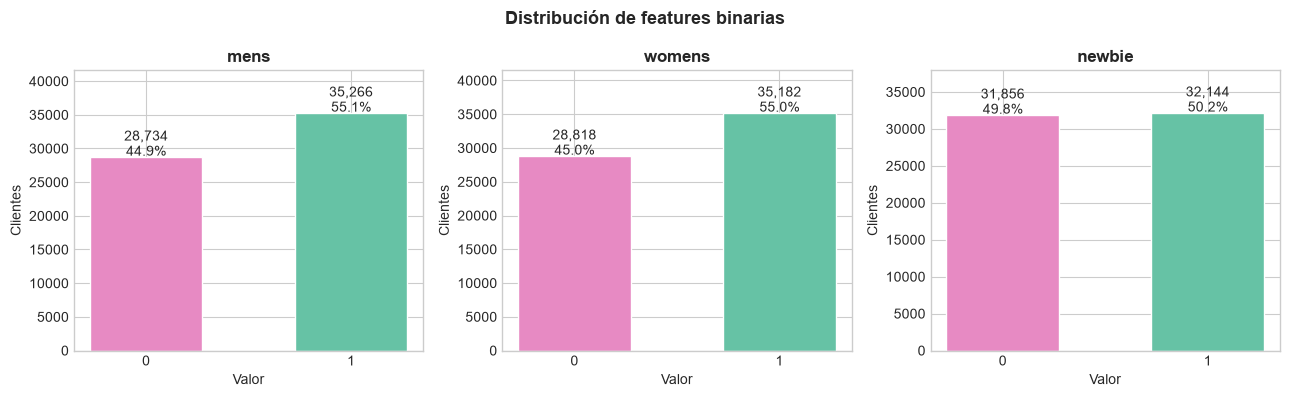

Variable,N (=0),N (=1),% positivos,% negativos
mens,"28,734","35,266",55.10%,44.90%
womens,"28,818","35,182",54.97%,45.03%
newbie,"31,856","32,144",50.22%,49.78%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, BIN_FEATURES):
    n0, n1 = int((df[col]==0).sum()), int((df[col]==1).sum())
    bars = ax.bar(["0", "1"], [n0, n1], color=[PALETTE[3], PALETTE[0]],
                  edgecolor="white", width=0.55)
    for bar, v in zip(bars, [n0, n1]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+200,
                f"{v:,}\n{v/len(df)*100:.1f}%", ha="center", fontsize=10)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_ylabel("Clientes")
    ax.set_ylim(0, max(n0,n1)*1.18)
    ax.set_xlabel("Valor")

plt.suptitle("Distribución de features binarias", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Summary table
bin_summary = pd.DataFrame([
    {"Variable":c, "N (=0)":int((df[c]==0).sum()), "N (=1)":int((df[c]==1).sum()),
     "% positivos":f"{df[c].mean()*100:.2f}%",
     "% negativos":f"{(1-df[c].mean())*100:.2f}%"}
    for c in BIN_FEATURES
])
display(bin_summary.style.format({"N (=0)":"{:,}","N (=1)":"{:,}"})
        .set_caption("Resumen de features binarias").hide(axis="index"))

In [5]:
# Co-ocurrencia mens × womens (¿puede un cliente tener ambos?)
ct_mw = pd.crosstab(df["mens"], df["womens"],
                    rownames=["mens"], colnames=["womens"])
print("Co-ocurrencia mens × womens:")
display(ct_mw)
print()
n_both  = ((df["mens"]==1) & (df["womens"]==1)).sum()
n_none  = ((df["mens"]==0) & (df["womens"]==0)).sum()
n_men   = ((df["mens"]==1) & (df["womens"]==0)).sum()
n_women = ((df["mens"]==0) & (df["womens"]==1)).sum()
for label, n in [("Solo mens","men"), ("Solo womens","women"), ("Ambos","both"), ("Ninguno","none")]:
    val = n_men if label=="Solo mens" else n_women if label=="Solo womens" else n_both if label=="Ambos" else n_none
    print(f"  {label:<15}: {val:,}  ({val/len(df)*100:.2f}%)")

Co-ocurrencia mens × womens:


womens,0,1
mens,,
0,0,28734
1,28818,6448



  Solo mens      : 28,818  (45.03%)
  Solo womens    : 28,734  (44.90%)
  Ambos          : 6,448  (10.08%)
  Ninguno        : 0  (0.00%)


## 3. Análisis Bivariado — Features Categóricas × Targets Binarios

───────────────────────────────────────────────────────  history_segment


history_segment,n,visit_rate_%,conv_rate_%,spend_mean
1) $0 - $100,"22,970",12.35%,0.71%,0.9059
2) $100 - $200,"14,254",12.78%,0.69%,0.8067
3) $200 - $350,"12,289",16.67%,0.95%,1.0022
4) $350 - $500,"6,409",19.32%,1.34%,1.4892
5) $500 - $750,"4,911",16.41%,1.16%,1.3326
"6) $750 - $1,000","1,859",19.31%,1.45%,1.0878
"7) $1,000 +","1,308",21.79%,2.14%,3.4591


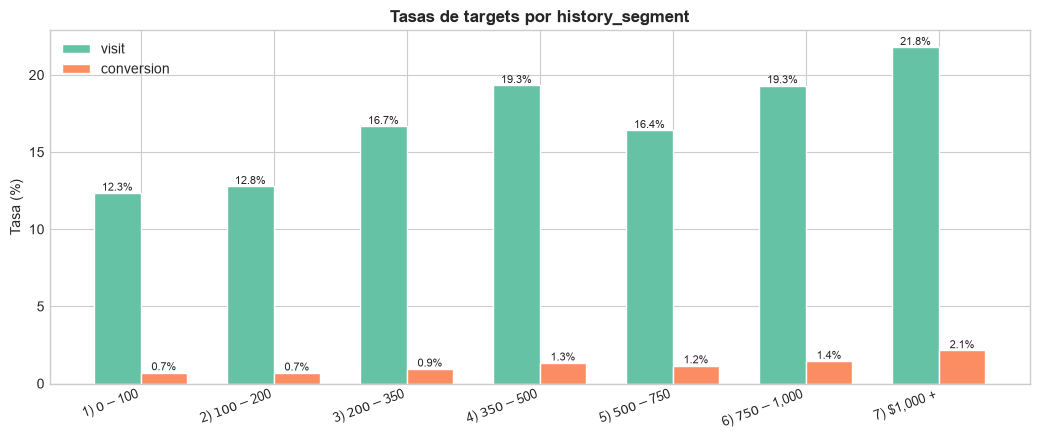


───────────────────────────────────────────────────────  zip_code


zip_code,n,visit_rate_%,conv_rate_%,spend_mean
Rural,"9,563",18.81%,1.12%,1.1946
Surburban,"28,776",13.99%,0.83%,0.9943
Urban,"25,661",13.90%,0.90%,1.0609


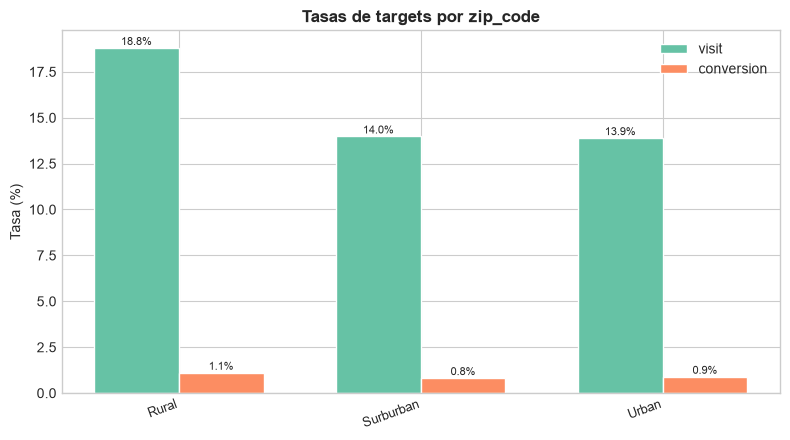


───────────────────────────────────────────────────────  channel


channel,n,visit_rate_%,conv_rate_%,spend_mean
Multichannel,"7,762",17.17%,1.26%,1.4018
Phone,"28,021",12.72%,0.77%,0.9089
Web,"28,217",15.94%,0.93%,1.0954


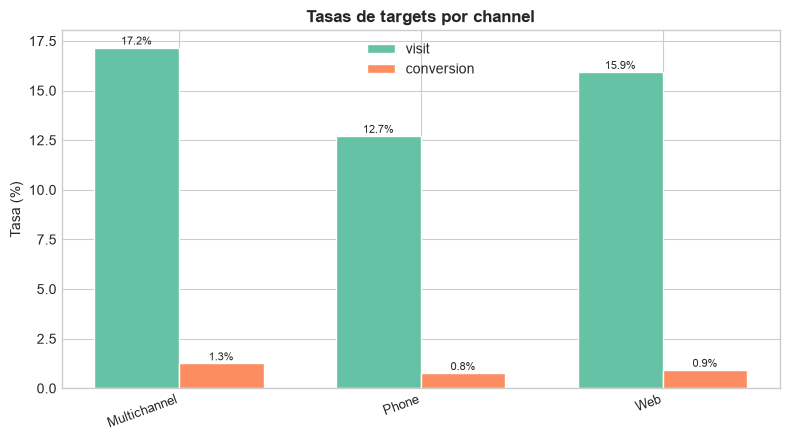

In [6]:
def target_rates_by_cat(col, order=None):
    grp = df.groupby(col)[BINARY_TGT + ["spend"]].agg(
        visit_rate    = ("visit",      "mean"),
        conv_rate     = ("conversion", "mean"),
        spend_mean    = ("spend",      "mean"),
        n             = ("visit",      "count"),
    ).reset_index()
    if order:
        grp[col] = pd.Categorical(grp[col], categories=order, ordered=True)
        grp = grp.sort_values(col)
    grp["visit_rate_%"] = (grp["visit_rate"]*100).round(2)
    grp["conv_rate_%"]  = (grp["conv_rate"] *100).round(2)
    return grp

def plot_target_rates(col, grp, title):
    x  = np.arange(len(grp))
    w  = 0.35
    fig, ax = plt.subplots(figsize=(max(8, len(grp)*1.5), 4.5))
    b1 = ax.bar(x - w/2, grp["visit_rate_%"],    w, label="visit",      color=PALETTE[0], edgecolor="white")
    b2 = ax.bar(x + w/2, grp["conv_rate_%"],     w, label="conversion", color=PALETTE[1], edgecolor="white")
    for bars in [b1, b2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x()+bar.get_width()/2, h+0.15, f"{h:.1f}%",
                    ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(grp[col].tolist(), rotation=20, ha="right", fontsize=9)
    ax.set_ylabel("Tasa (%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

for col, order, title in [
    ("history_segment", HS_ORDER,  "Tasas de targets por history_segment"),
    ("zip_code",        None,       "Tasas de targets por zip_code"),
    ("channel",         None,       "Tasas de targets por channel"),
]:
    grp = target_rates_by_cat(col, order)
    print(f"{'─'*55}  {col}")
    display(grp[[col,"n","visit_rate_%","conv_rate_%","spend_mean"]].style
            .format({"n":"{:,}","visit_rate_%":"{:.2f}%","conv_rate_%":"{:.2f}%","spend_mean":"{:.4f}"})
            .hide(axis="index"))
    plot_target_rates(col, grp, title)
    print()

## 4. Análisis Bivariado — Features Binarias × Targets

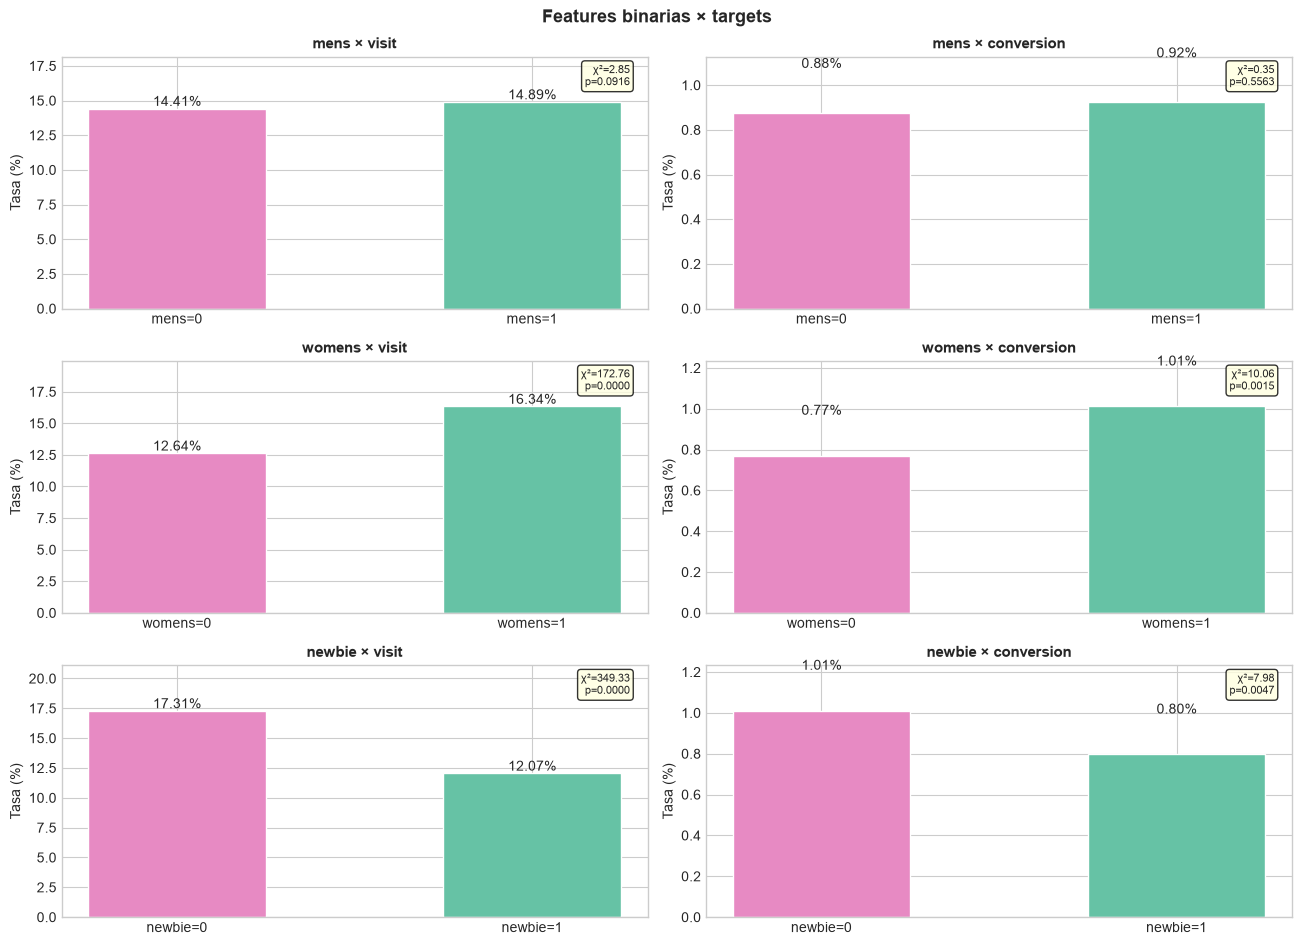

In [7]:
fig, axes = plt.subplots(len(BIN_FEATURES), 2, figsize=(13, len(BIN_FEATURES)*3.2))
if len(BIN_FEATURES) == 1: axes = [axes]

for row, feat in enumerate(BIN_FEATURES):
    for col_idx, tgt in enumerate(BINARY_TGT):
        ax = axes[row][col_idx]
        rates = df.groupby(feat)[tgt].mean() * 100
        bars  = ax.bar([f"{feat}=0", f"{feat}=1"], [rates.get(0,0), rates.get(1,0)],
                       color=[PALETTE[3], PALETTE[0]], edgecolor="white", width=0.5)
        for bar, v in zip(bars, [rates.get(0,0), rates.get(1,0)]):
            ax.text(bar.get_x()+bar.get_width()/2, v+0.2,
                    f"{v:.2f}%", ha="center", fontsize=10)
        ax.set_title(f"{feat} × {tgt}", fontsize=11, fontweight="bold")
        ax.set_ylabel("Tasa (%)")
        ax.set_ylim(0, max(rates.values)*1.22)
        # Chi-square test
        ct = pd.crosstab(df[feat], df[tgt])
        chi2, p, _, _ = chi2_contingency(ct)
        ax.text(0.97, 0.97, f"χ²={chi2:.2f}\np={p:.4f}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8,
                bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))

plt.suptitle("Features binarias × targets", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Tests Chi-Cuadrado — Independencia entre Features Categóricas y Targets

In [8]:
chi2_results = []
for feat in ALL_CAT:
    for tgt in BINARY_TGT:
        ct = pd.crosstab(df[feat], df[tgt])
        chi2, p, dof, _ = chi2_contingency(ct)
        n = len(df)
        k = min(ct.shape) - 1
        cramers = np.sqrt(chi2 / (n * k)) if k > 0 else 0
        chi2_results.append({
            "Feature": feat, "Target": tgt,
            "χ²": chi2, "p-valor": p, "dof": dof,
            "Cramér's V": cramers,
            "Significativo (α=0.05)": "Sí ✓" if p < 0.05 else "No",
        })

chi2_df = pd.DataFrame(chi2_results)
display(chi2_df.style
    .format({"χ²":"{:.2f}", "p-valor":"{:.6f}", "Cramér's V":"{:.4f}"})
    .background_gradient(subset=["Cramér's V"], cmap="RdYlGn")
    .set_caption("Tests χ² de independencia — features categóricas × targets")
    .hide(axis="index")
)

Feature,Target,χ²,p-valor,dof,Cramér's V,Significativo (α=0.05)
history_segment,visit,385.94,0.000000,6,0.0777,Sí ✓
history_segment,conversion,62.51,0.000000,6,0.0313,Sí ✓
zip_code,visit,153.51,0.000000,2,0.0490,Sí ✓
zip_code,conversion,6.67,0.035643,2,0.0102,Sí ✓
channel,visit,160.70,0.000000,2,0.0501,Sí ✓
channel,conversion,16.66,0.000242,2,0.0161,Sí ✓
mens,visit,2.85,0.091644,1,0.0067,No
mens,conversion,0.35,0.556282,1,0.0023,No
womens,visit,172.76,0.000000,1,0.0520,Sí ✓
womens,conversion,10.06,0.001517,1,0.0125,Sí ✓


## 6. Asociación entre Features Categóricas — Cramér's V

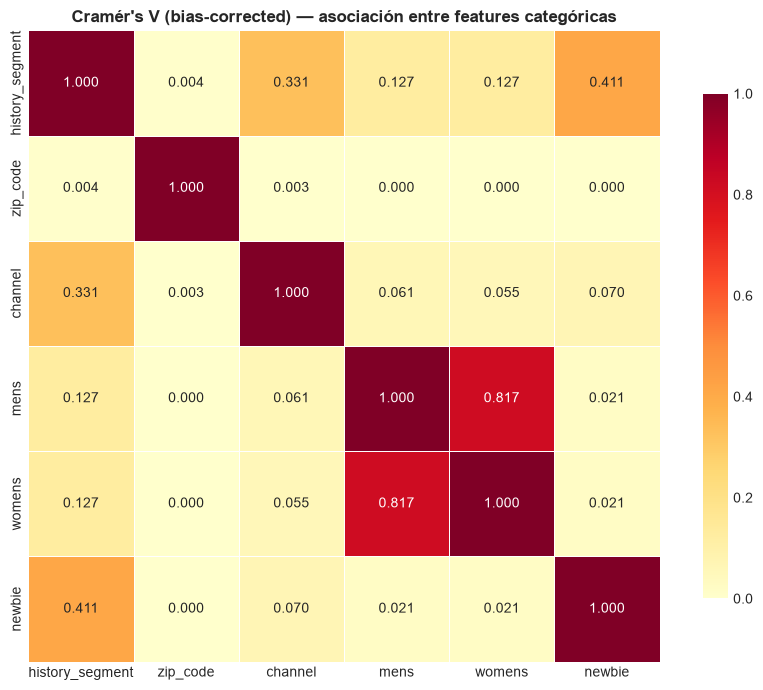

Interpretación Cramér's V:  0.0 = sin asociación | 0.1 = débil | 0.3 = moderada | 0.5+ = fuerte

Top 5 asociaciones más fuertes:
  mens ↔ womens: 0.8169
  history_segment ↔ newbie: 0.4105
  history_segment ↔ channel: 0.3310
  history_segment ↔ womens: 0.1273
  history_segment ↔ mens: 0.1272


In [9]:
def cramers_v_corrected(x, y):
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct, correction=False)
    n = len(x)
    r, k = ct.shape
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k-1)*(r-1)/(n-1))
    r_corr = r - (r-1)**2/(n-1)
    k_corr = k - (k-1)**2/(n-1)
    denom = min(k_corr-1, r_corr-1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else 0

cramers_matrix = pd.DataFrame(index=ALL_CAT, columns=ALL_CAT, dtype=float)
for c1 in ALL_CAT:
    for c2 in ALL_CAT:
        cramers_matrix.loc[c1, c2] = cramers_v_corrected(
            df[c1].astype(str), df[c2].astype(str))

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(cramers_matrix.values, dtype=bool), k=1)
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".3f",
            cmap="YlOrRd", vmin=0, vmax=1, ax=ax,
            linewidths=0.5, square=True, cbar_kws={"shrink":0.8})
ax.set_title("Cramér's V (bias-corrected) — asociación entre features categóricas",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

print("Interpretación Cramér's V:  0.0 = sin asociación | 0.1 = débil | 0.3 = moderada | 0.5+ = fuerte")
print()
# Top asociaciones
mask_upper = np.triu(np.ones_like(cramers_matrix.values, dtype=bool), k=1)
pairs = [(ALL_CAT[i], ALL_CAT[j], cramers_matrix.values[i,j])
         for i in range(len(ALL_CAT)) for j in range(i+1, len(ALL_CAT))]
pairs.sort(key=lambda x: x[2], reverse=True)
print("Top 5 asociaciones más fuertes:")
for c1, c2, v in pairs[:5]:
    print(f"  {c1} ↔ {c2}: {v:.4f}")

## 7. Balance del RCT — Features Categóricas por Grupo de Tratamiento

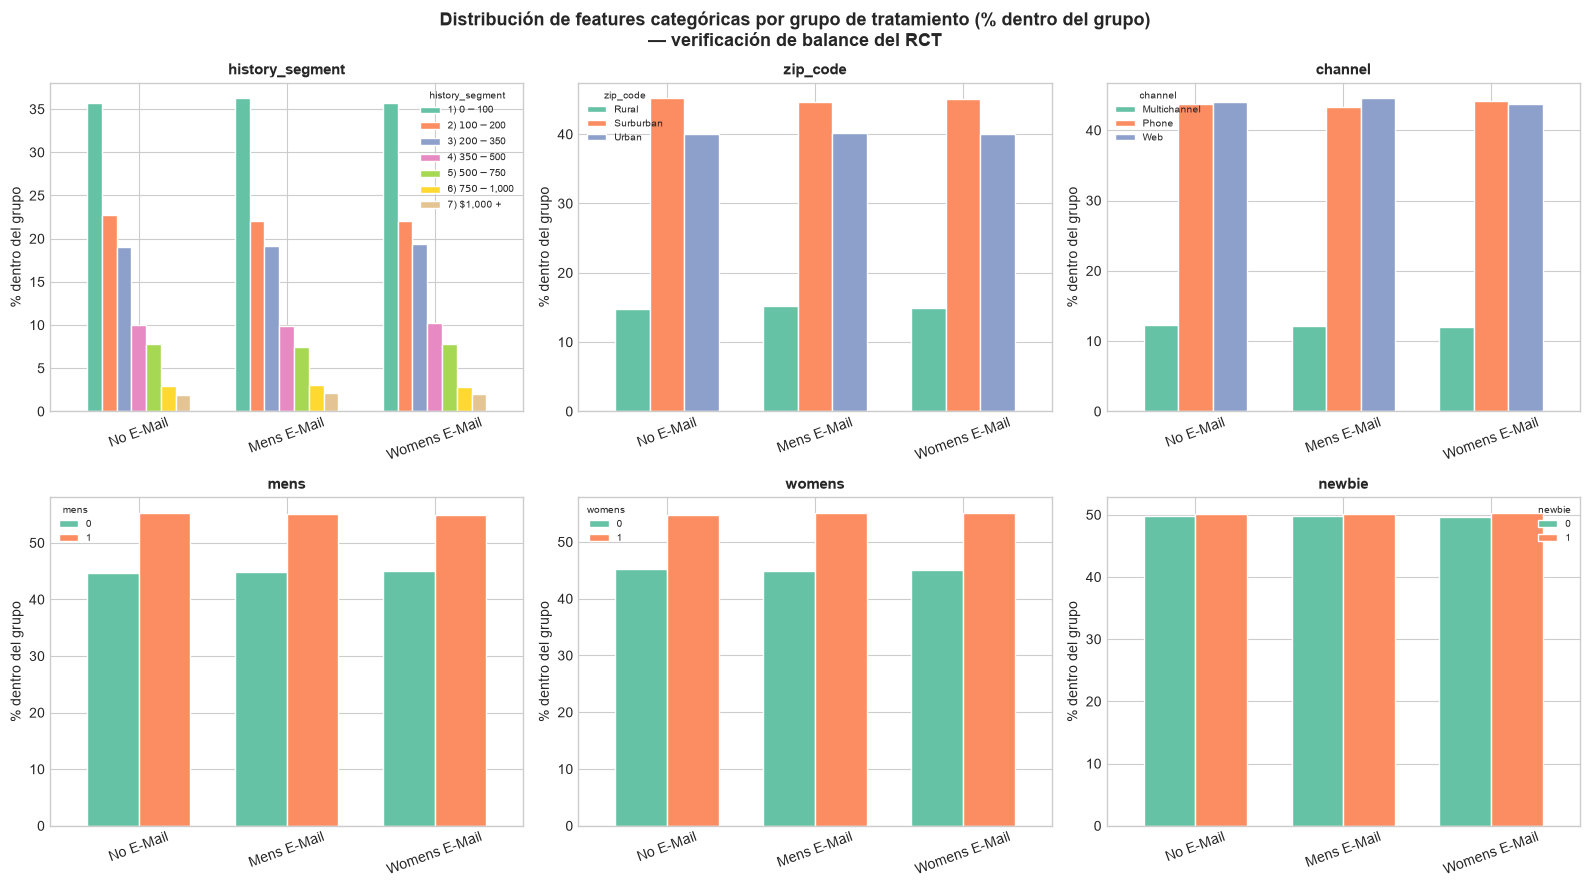

Test χ² feature × segmento (H₀: feature independiente del grupo de tratamiento):
  history_segment     : χ²=  13.15  p=0.357998  → ✓ Balanceado
  zip_code            : χ²=   2.87  p=0.579479  → ✓ Balanceado
  channel             : χ²=   3.63  p=0.458034  → ✓ Balanceado
  mens                : χ²=   0.80  p=0.671664  → ✓ Balanceado
  womens              : χ²=   0.63  p=0.728869  → ✓ Balanceado
  newbie              : χ²=   0.14  p=0.933855  → ✓ Balanceado


In [10]:
ORDER_SEG = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.flatten(), ALL_CAT):
    grp = df.groupby([SEGMENT_COL, feat]).size().unstack(fill_value=0)
    grp_pct = grp.div(grp.sum(axis=1), axis=0) * 100
    grp_pct.reindex(ORDER_SEG).plot(kind="bar", ax=ax, edgecolor="white", width=0.7)
    ax.set_title(feat, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% dentro del grupo")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=7, title=feat, title_fontsize=7)

plt.suptitle("Distribución de features categóricas por grupo de tratamiento (% dentro del grupo)\n"
             "— verificación de balance del RCT", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Chi-square tests de independencia feature × segment
print("Test χ² feature × segmento (H₀: feature independiente del grupo de tratamiento):")
for feat in ALL_CAT:
    ct = pd.crosstab(df[feat], df[SEGMENT_COL])
    chi2, p, _, _ = chi2_contingency(ct)
    state = "✓ Balanceado" if p > 0.05 else "⚠ Desbalanceado"
    print(f"  {feat:<20}: χ²={chi2:7.2f}  p={p:.6f}  → {state}")

## 8. Poder Predictivo Individual — AUC-ROC por Feature

In [11]:
def target_encode_auc(col, tgt):
    rates  = df.groupby(col)[tgt].mean()
    scores = df[col].map(rates).values
    y      = df[tgt].values
    auc    = roc_auc_score(y, scores)
    return max(auc, 1 - auc)

def ordinal_encode_auc(col, order, tgt):
    mapping = {cat: i for i, cat in enumerate(order)}
    scores  = df[col].map(mapping).values
    y       = df[tgt].values
    auc     = roc_auc_score(y, scores)
    return max(auc, 1 - auc)

def binary_auc(col, tgt):
    scores = df[col].values.astype(float)
    y      = df[tgt].values
    auc    = roc_auc_score(y, scores)
    return max(auc, 1 - auc)

# --- Categorical features
auc_cat_results = []
for feat in ALL_CAT:
    for tgt in BINARY_TGT:
        if feat == "history_segment":
            auc = ordinal_encode_auc(feat, HS_ORDER, tgt)
        elif feat in BIN_FEATURES:
            auc = binary_auc(feat, tgt)
        else:
            auc = target_encode_auc(feat, tgt)
        auc_cat_results.append({"Feature":feat, "Target":tgt, "AUC-ROC":auc})

# --- Numerical features (for combined table)
from sklearn.metrics import roc_auc_score as roc_auc
for feat in NUM_FEATURES:
    for tgt in BINARY_TGT:
        auc = roc_auc(df[tgt], df[feat])
        auc = max(auc, 1-auc)
        auc_cat_results.append({"Feature":feat, "Target":tgt, "AUC-ROC":auc})

auc_all_df  = pd.DataFrame(auc_cat_results)
auc_pivot   = auc_all_df.pivot(index="Feature", columns="Target", values="AUC-ROC")
auc_pivot["Media"] = auc_pivot.mean(axis=1)
auc_pivot   = auc_pivot.sort_values("Media", ascending=False)

display(auc_pivot.style
    .format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=None, vmin=0.5, vmax=0.75)
    .set_caption("Poder predictivo individual — AUC-ROC (todas las features, ordenado por media)")
)
print()
print("Interpretación: AUC-ROC 0.50 = azar | 0.60 = moderado | 0.70+ = bueno")

Target,conversion,visit,Media
Feature,,,
recency,0.5764,0.5614,0.5689
history,0.5775,0.5572,0.5673
history_segment,0.5748,0.5549,0.5649
newbie,0.5299,0.5522,0.5411
channel,0.5414,0.5369,0.5391
womens,0.5334,0.5366,0.5350
zip_code,0.5254,0.5253,0.5254
mens,0.5066,0.5047,0.5056



Interpretación: AUC-ROC 0.50 = azar | 0.60 = moderado | 0.70+ = bueno


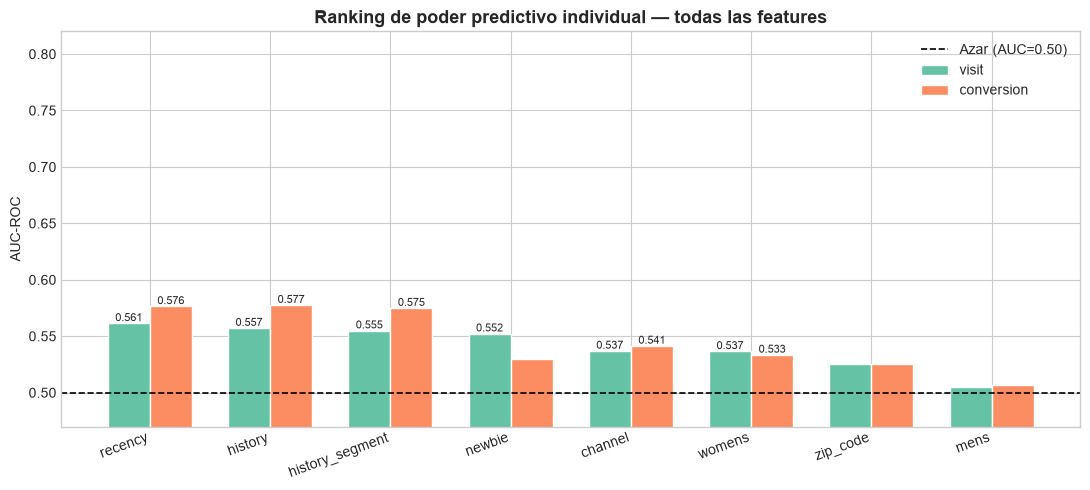

In [12]:
# Visualización del ranking de poder predictivo
fig, ax = plt.subplots(figsize=(11, 5))
features_sorted = auc_pivot.index.tolist()
x = np.arange(len(features_sorted))
w = 0.35
for i, tgt in enumerate(BINARY_TGT):
    vals = [auc_pivot.loc[f, tgt] for f in features_sorted]
    bars = ax.bar(x + i*w - w/2, vals, w, label=tgt, color=PALETTE[i], edgecolor="white")
    for bar, v in zip(bars, vals):
        if v > 0.53:
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                    f"{v:.3f}", ha="center", fontsize=8, rotation=0)

ax.axhline(0.5, color="black", ls="--", lw=1.2, label="Azar (AUC=0.50)")
ax.set_xticks(x)
ax.set_xticklabels(features_sorted, rotation=20, ha="right", fontsize=10)
ax.set_ylabel("AUC-ROC")
ax.set_ylim(0.47, 0.82)
ax.set_title("Ranking de poder predictivo individual — todas las features",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [13]:
# F1 con Logistic Regression univariada para features categóricas
f1_cat_results = []
for feat in ALL_CAT:
    if feat == "history_segment":
        mapping = {cat: i for i, cat in enumerate(HS_ORDER)}
        X_enc   = df[feat].map(mapping).values.reshape(-1,1)
    elif feat in BIN_FEATURES:
        X_enc = df[feat].values.reshape(-1,1)
    else:
        enc   = OrdinalEncoder()
        X_enc = enc.fit_transform(df[[feat]])

    for tgt in BINARY_TGT:
        y    = df[tgt].values
        scl  = StandardScaler()
        X_sc = scl.fit_transform(X_enc)
        lr   = LogisticRegression(class_weight="balanced", random_state=42, max_iter=500)
        ypred = cross_val_predict(lr, X_sc, y, cv=5, method="predict")
        f1   = f1_score(y, ypred)
        f1_cat_results.append({"Feature":feat, "Target":tgt, "F1 (LR, balanced)":f1})

f1_cat_pivot = pd.DataFrame(f1_cat_results).pivot(
    index="Feature", columns="Target", values="F1 (LR, balanced)")
f1_cat_pivot["Media"] = f1_cat_pivot.mean(axis=1)
f1_cat_pivot = f1_cat_pivot.sort_values("Media", ascending=False)

display(f1_cat_pivot.style
    .format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=None)
    .set_caption("F1-score — LR univariada con class_weight=balanced (cv=5), features categóricas")
)

Target,conversion,visit,Media
Feature,,,
newbie,0.0199,0.2673,0.1436
history_segment,0.0230,0.2619,0.1425
womens,0.0199,0.2580,0.1389
zip_code,0.0178,0.2441,0.1309
channel,0.0173,0.2392,0.1283
mens,0.0182,0.2352,0.1267


## 9. Feature Selection — Boruta (TODAS las Features del Dataset)

In [14]:
try:
    from boruta import BorutaPy
    from sklearn.ensemble import RandomForestClassifier
    HAS_BORUTA = True
except ImportError:
    HAS_BORUTA = False
    print("Instalar con: poetry add Boruta")

if HAS_BORUTA:
    # Codificar todas las features
    enc_hs   = {cat: i for i, cat in enumerate(HS_ORDER)}
    enc_zip  = OrdinalEncoder()
    enc_ch   = OrdinalEncoder()

    X_parts = {
        "recency"         : df["recency"].values.reshape(-1,1),
        "history"         : df["history"].values.reshape(-1,1),
        "mens"            : df["mens"].values.reshape(-1,1),
        "womens"          : df["womens"].values.reshape(-1,1),
        "newbie"          : df["newbie"].values.reshape(-1,1),
        "history_segment" : df["history_segment"].map(enc_hs).values.reshape(-1,1),
        "zip_code"        : enc_zip.fit_transform(df[["zip_code"]]),
        "channel"         : enc_ch.fit_transform(df[["channel"]]),
    }
    feat_names = list(X_parts.keys())
    X_all = np.hstack(list(X_parts.values()))

    boruta_res = {}
    for tgt in BINARY_TGT:
        y  = df[tgt].values
        rf = RandomForestClassifier(n_estimators=150, max_depth=7,
                                    random_state=42, n_jobs=-1, class_weight="balanced")
        bs = BorutaPy(rf, n_estimators="auto", verbose=0,
                      random_state=42, max_iter=100, alpha=0.05)
        bs.fit(X_all, y)
        boruta_res[tgt] = {
            "support"  : bs.support_,
            "tentative": bs.support_weak_,
            "ranking"  : bs.ranking_,
        }

    print("═"*65)
    print("  BORUTA — Todas las features del dataset")
    print("═"*65)
    for tgt, res in boruta_res.items():
        rows = []
        for feat, sup, tent, rank in zip(feat_names, res["support"], res["tentative"], res["ranking"]):
            estado = "✓ Confirmada" if sup else ("○ Tentativa" if tent else "✗ Rechazada")
            rows.append({"Feature":feat, "Estado":estado, "Ranking":rank})
        b_df = pd.DataFrame(rows).sort_values("Ranking")
        print(f"\n  TARGET: {tgt.upper()}")
        display(b_df.style
            .applymap(lambda v: "color:green;font-weight:bold" if "Confirmada" in str(v) else
                               ("color:orange" if "Tentativa" in str(v) else "color:red"),
                      subset=["Estado"])
            .hide(axis="index")
        )

═════════════════════════════════════════════════════════════════
  BORUTA — Todas las features del dataset
═════════════════════════════════════════════════════════════════

  TARGET: VISIT


Feature,Estado,Ranking
recency,✓ Confirmada,1
history,✓ Confirmada,1
womens,✓ Confirmada,1
newbie,✓ Confirmada,1
history_segment,✓ Confirmada,1
zip_code,✗ Rechazada,2
mens,✗ Rechazada,3
channel,✗ Rechazada,4



  TARGET: CONVERSION


Feature,Estado,Ranking
history,✓ Confirmada,1
recency,✗ Rechazada,2
history_segment,✗ Rechazada,3
newbie,✗ Rechazada,4
zip_code,✗ Rechazada,5
channel,✗ Rechazada,5
womens,✗ Rechazada,7
mens,✗ Rechazada,8


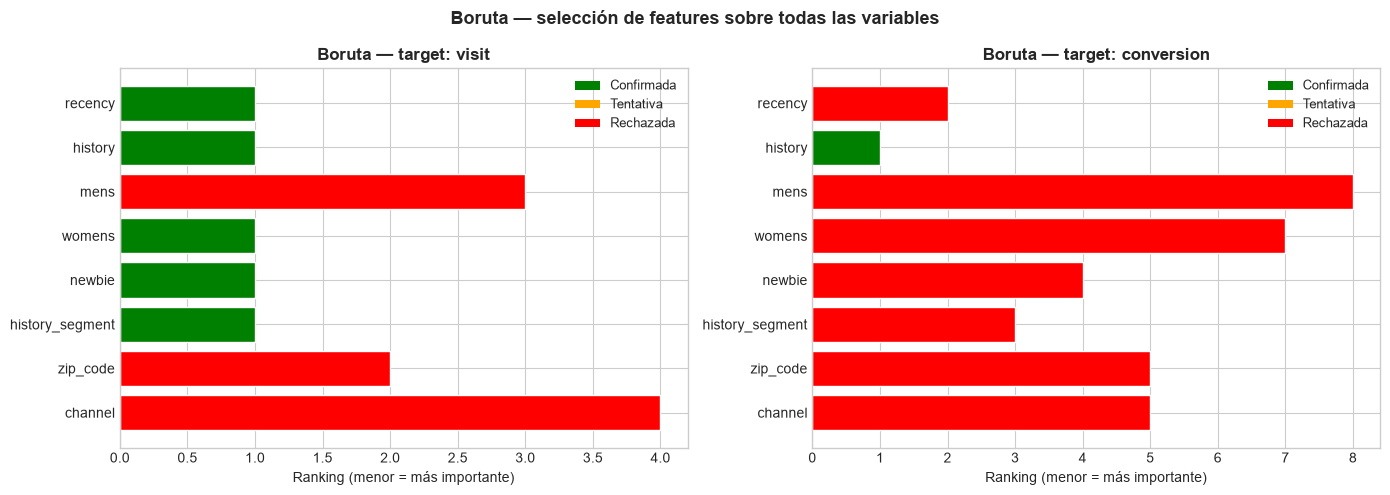

In [15]:
if HAS_BORUTA:
    # Visualización conjunta de resultados Boruta
    states = {"✓ Confirmada": 3, "○ Tentativa": 2, "✗ Rechazada": 1}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, tgt in zip(axes, BINARY_TGT):
        res  = boruta_res[tgt]
        vals = []
        for sup, tent in zip(res["support"], res["tentative"]):
            vals.append(3 if sup else (2 if tent else 1))
        colors_b = ["green" if v==3 else ("orange" if v==2 else "red") for v in vals]
        ax.barh(feat_names, res["ranking"], color=colors_b, edgecolor="white")
        ax.set_title(f"Boruta — target: {tgt}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Ranking (menor = más importante)")
        ax.invert_yaxis()
        from matplotlib.patches import Patch
        legend_elements = [Patch(facecolor="green",  label="Confirmada"),
                           Patch(facecolor="orange", label="Tentativa"),
                           Patch(facecolor="red",    label="Rechazada")]
        ax.legend(handles=legend_elements, fontsize=9)
    plt.suptitle("Boruta — selección de features sobre todas las variables",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 10. Síntesis Ejecutiva

In [16]:
print("═"*65)
print("  SÍNTESIS — FEATURES CATEGÓRICAS Y BINARIAS")
print("═"*65)
print()
print("  1. DISTRIBUCIÓN:")
for feat in ALL_CAT:
    print(f"    {feat:<20}: {df[feat].nunique()} valores únicos — moda: {df[feat].mode()[0]}")

print()
print("  2. PODER PREDICTIVO (AUC-ROC, visit | conversion):")
for feat in auc_pivot.index:
    av = auc_pivot.loc[feat, "visit"]
    ac = auc_pivot.loc[feat, "conversion"]
    print(f"    {feat:<22}: visit={av:.4f} | conv={ac:.4f}")

print()
print("  3. CO-OCURRENCIA mens × womens:")
n_both_b = ((df["mens"]==1)&(df["womens"]==1)).sum()
print(f"    Ambos = 1: {n_both_b:,} ({n_both_b/len(df)*100:.2f}%)")

print()
print("  4. TYPO CONOCIDO: zip_code='Surburban' (original del dataset)")
print("═"*65)

═════════════════════════════════════════════════════════════════
  SÍNTESIS — FEATURES CATEGÓRICAS Y BINARIAS
═════════════════════════════════════════════════════════════════

  1. DISTRIBUCIÓN:
    history_segment     : 7 valores únicos — moda: 1) $0 - $100
    zip_code            : 3 valores únicos — moda: Surburban
    channel             : 3 valores únicos — moda: Web
    mens                : 2 valores únicos — moda: 1
    womens              : 2 valores únicos — moda: 1
    newbie              : 2 valores únicos — moda: 1

  2. PODER PREDICTIVO (AUC-ROC, visit | conversion):
    recency               : visit=0.5614 | conv=0.5764
    history               : visit=0.5572 | conv=0.5775
    history_segment       : visit=0.5549 | conv=0.5748
    newbie                : visit=0.5522 | conv=0.5299
    channel               : visit=0.5369 | conv=0.5414
    womens                : visit=0.5366 | conv=0.5334
    zip_code              : visit=0.5253 | conv=0.5254
    mens                 

---
## Conclusión

- **`history_segment`** y **`history`** (numérica) son las features con mayor poder predictivo individual, lo que tiene sentido: el historial de gasto previo es el mejor predictor de compra futura.
- **`channel`** muestra diferencias notables en tasas de conversión entre categorías — los clientes multicanal tienen comportamientos distintos.
- Las features `mens` y `womens` tienen correlación baja con los targets globales, pero pueden interactuar con el tratamiento (el email de moda masculina puede ser más efectivo para clientes con historial `mens=1`).
- **Balance del RCT verificado**: ninguna feature categórica está significativamente desbalanceada entre los tres grupos de tratamiento.
- **Boruta** confirmará qué features aportan información incremental real más allá del ruido — los resultados guiarán la ingeniería de features (Feature Engineering, Notebook 05).

> *Este es el último notebook del EDA. El siguiente paso es Feature Engineering.*